In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pickle as pickle
import os
import import_ipynb
from matplotlib.patches import FancyArrowPatch
import ipynb.fs.full.ssiProjectModule as ssiMod
import importlib as imp
imp.reload(ssiMod)
import itertools
import matplotlib as mpl
mpl.rcParams['font.size']=15
from scipy.stats import circmean
np.random.seed(0)
from scipy.optimize import curve_fit


theta_step = 2

exp_dir = 'C:/Users/Carlo PARIS/00PhD Code/CoSyne/'

main_dir = 'C:/Users/Carlo PARIS/00PhD Code/'
dat_dir_out = 'C:/Users/Carlo PARIS/00PhD Code/0Paper plots/Figure1/'
title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240509_AREA.pkl'

with open(dat_dir_out+title, 'rb') as rick:
    data_dict = pickle.load(rick)
bio_idx = np.where(data_dict['all_multipliers']==1.)[0][0]
print(data_dict.keys())

colors=['blue', 'green','red', 'gold' ]
example_quads = [201, 125]

dict_keys(['all_multipliers', 'all_quad_pars', 'all_quad_tc', 'all_ssis', 'all_quad_fwhm', 'exp_quad_list', 'all_quad_vm_fit_pars', 'all_quad_raw_mean_tcs', 'all_quad_raw_mean_stds', 'original_cell_idx_quads', 'is_bio_quad'])


In [2]:
stim = np.arange(0,360,10)
ex_raw_quad_tc = np.copy(data_dict['all_quad_raw_mean_tcs'][example_quads])/1.6
ex_raw_quad_std = np.copy(data_dict['all_quad_raw_mean_stds'][example_quads])/1.6

color_pallette = ['blue', 'green', 'red', 'gold']
radius = 5

# get all preferred directions
mus = np.unique(data_dict['all_quad_pars'][:,bio_idx, :,1].flatten())
# get quadrant of preferred direction for every cell
mu_quadrant = np.array([int(((el%360+45)%360))//90 for el in mus])
# get average preferred direction of every quadrant
mu_means = np.array([np.rad2deg(circmean(np.deg2rad(mus[np.where(mu_quadrant==q)[0]]))) for q in np.sort(np.unique(mu_quadrant))])
# 
mu_means_quadrants = np.array([int(((el+45)%360)//90) for el in mu_means])


In [3]:
def plot_arrow(ax, radius, angle_degrees,color):

    # Convert angle from degrees to radians
    angle_radians = np.deg2rad(angle_degrees)

    # Calculate arrow endpoint
    arrow_end_x = 1.0*radius * np.cos(angle_radians)
    arrow_end_y = 1.0*radius * np.sin(angle_radians)

    # Plot the arrow
    arrow = FancyArrowPatch((arrow_end_x, arrow_end_y),(0, 0), \
                            color=color, arrowstyle='<-', linewidth = 2, mutation_scale=30)
    ax.add_artist(arrow)


def plot_circle_with_arrows(radius, angle_degrees_array, colors, ax):
    
    circle = plt.Circle((0,0), radius, color = 'grey', linestyle = 'dashed', fill = False)
    ax.add_artist(circle)
    # Set aspect ratio to equal and adjust limits
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlim(-radius - 1, radius + 1)
    ax.set_ylim(-radius - 1, radius + 1)
    ax.set_axis_off()  # Turn off axes
    if np.array(angle_degrees_array).size:
        for i, angle in enumerate(np.atleast_1d(angle_degrees_array)):
            plot_arrow(ax, radius, angle, colors[i])


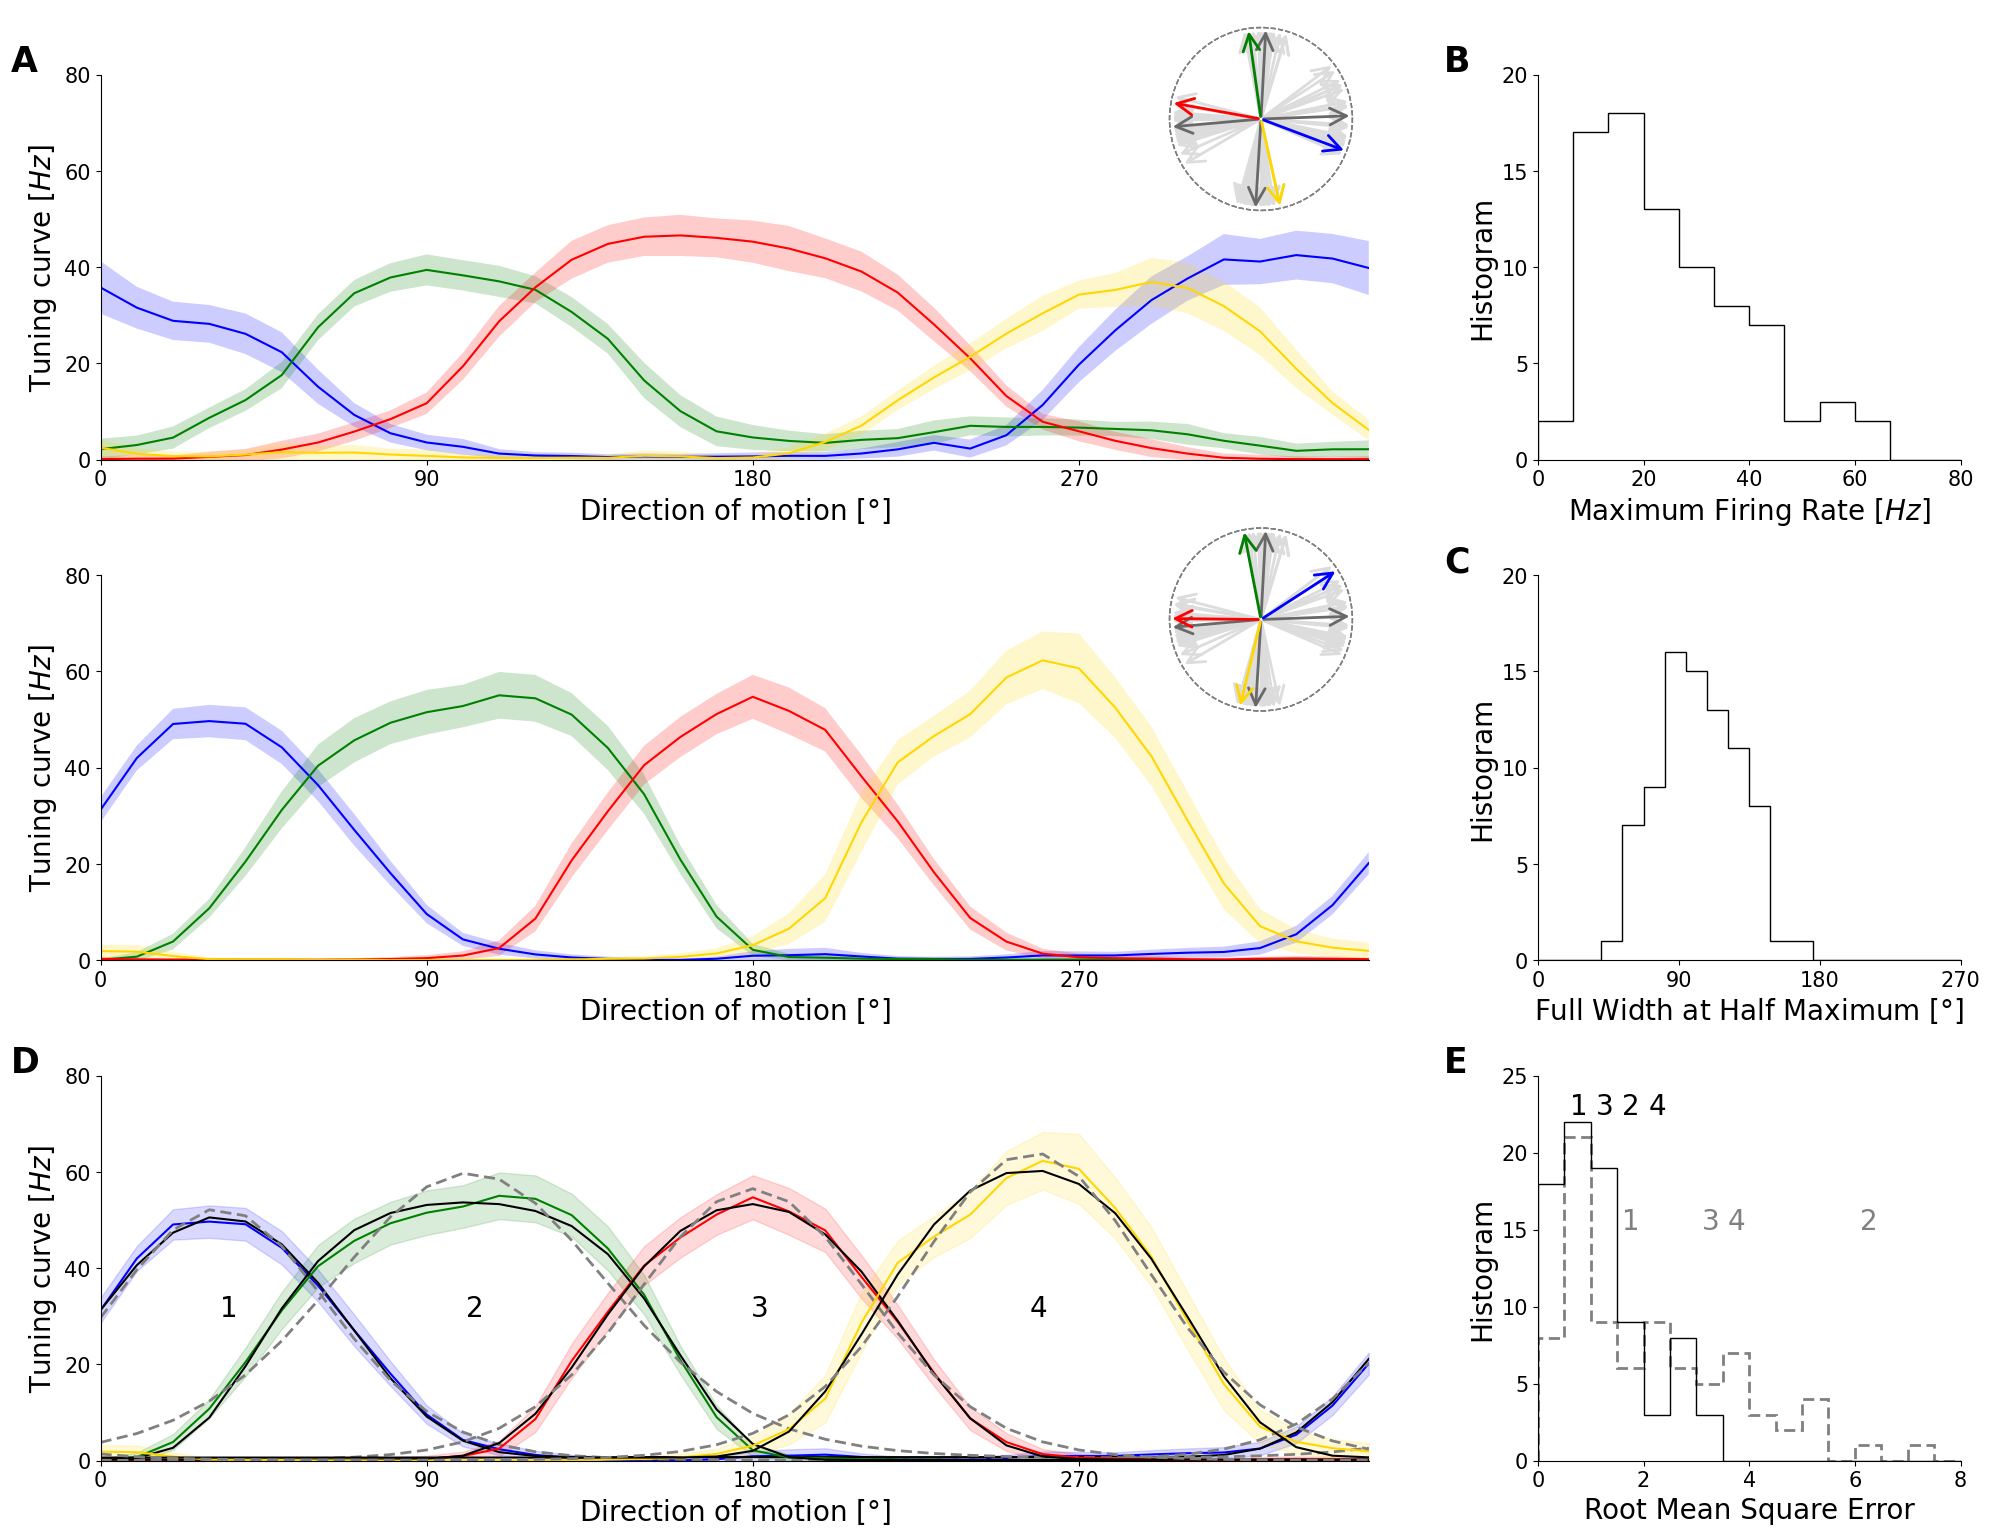

In [4]:
fig = plt.figure(figsize = (24, 18))
gs = gridspec.GridSpec(3,2, width_ratios = (3,1), wspace = 0.2, hspace = 0.3)

ax_q1 = fig.add_subplot(gs[0,0])
ax_q2 = fig.add_subplot(gs[1,0])
ax_fit_q2 = fig.add_subplot(gs[2,0])

ax_maxfr = fig.add_subplot(gs[0,1])
ax_fwhm = fig.add_subplot(gs[1,1])
ax_vm_v_ftvm = fig.add_subplot(gs[2,1])

# PANEL 1.1

for quad, _ in enumerate(ex_raw_quad_tc):
    ax = [ax_q1, ax_q2][quad]
    lab = [r'$\bf{A}$', r'$\bf{B}$']
    for i, tc in enumerate(ex_raw_quad_tc[quad]):
        tc_std = ex_raw_quad_std[quad][i]
        ax.plot(stim, tc, color = colors[i])
        ax.fill_between(stim, tc-tc_std, tc+tc_std, 
                         color = colors[i], alpha = 0.2, edgecolor = None)


    ax.set_xticks(np.arange(0,361, 90))
    ax.set_yticks(np.arange(0, 81, 20))
    ax.tick_params(labelsize = 15)
    xmin, xmax, ymin, ymax = ax.axis()
    if quad==0: ax.text(-25, 1.01*ymax, lab[quad], size = 25)

    ax.set_xlabel(r'Direction of motion [$\degree$]', size = 20)
    ax.set_ylabel(r'Tuning curve [$Hz$]', size = 20)

    ax.set_xlim(0,350)
    ax.set_ylim(0,80)  
    
    
#     add preferred direction arrow distribution 
    ax_inset = ax.inset_axes([0.82, 0.6, 0.19, 0.57])
    plot_circle_with_arrows(radius, mus, ['gainsboro' for el in mus], ax_inset)
    plot_circle_with_arrows(radius, mu_means, ['dimgrey' for q in mu_means_quadrants], ax_inset)
    plot_circle_with_arrows(radius, \
                            data_dict['all_quad_pars'][example_quads[quad], bio_idx, :, 1],\
                            color_pallette, \
                            ax_inset)


# vm vs ftvm fits
which_cells = [0,1,2,3]
for single_quad in [example_quads[1]]:
    quad_tcs = data_dict['all_quad_raw_mean_tcs'][single_quad]/1.6
    quad_stds = data_dict['all_quad_raw_mean_stds'][single_quad]/1.6
    quad_vm = np.array([ssiMod.VON_MISES(stim, *pars) for pars in \
                        data_dict['all_quad_vm_fit_pars'][single_quad]])/1.6
    quad_ftvm = np.array([ssiMod.FTVM(stim, *pars) for pars in \
                          data_dict['all_quad_pars'][single_quad,bio_idx]])/1.6

    ax_fit_q2.set_xticks(np.arange(0,361, 90))
    ax_fit_q2.set_yticks(np.arange(0,81, 20))
    ax_fit_q2.set_xlabel(r'Direction of motion [$\degree$]', size = 20)
    ax_fit_q2.set_ylabel(r'Tuning curve [$Hz$]', size = 20)
    ax_fit_q2.set_xlim(0,350)
    ax_fit_q2.set_ylim(0,80)
    for i in which_cells:
        ax_fit_q2.plot(stim, quad_tcs[i], color = colors[i])
        ax_fit_q2.fill_between(stim, quad_tcs[i]-quad_stds[i], quad_tcs[i]+quad_stds[i], \
                         edgecolor = colors[i], color = colors[i], alpha = 0.15)
        ax_fit_q2.plot(stim, quad_ftvm[i], color = 'k', linestyle = 'solid')
        ax_fit_q2.plot(stim, quad_vm[i], color = 'grey', linestyle = (0,(4,2)), lw=2)
        ax_fit_q2.text(data_dict['all_quad_pars'][single_quad,bio_idx,i,1]%360, 30, \
                       str(i+1), fontsize =20, color = 'k')
        
    xmin, xmax, ymin, ymax = ax_fit_q2.axis()
    ax_fit_q2.text(-25, 1.01*ymax, r'$\bf{D}$', size = 25)
    

# Maximum firing rate histogram

raw_tcs = np.unique(np.reshape(np.copy(data_dict['all_quad_raw_mean_tcs']), \
                               (np.prod(data_dict['all_quad_raw_mean_tcs'].shape[:2]), \
                                data_dict['all_quad_raw_mean_tcs'].shape[-1])),axis = 0)
ax_maxfr.hist(raw_tcs.max(axis=1)/1.6, range = (0,100), bins = 15, histtype = 'step', \
              color = 'k')

ax_maxfr.set_xticks(np.arange(0,81, 20))
ax_maxfr.set_yticks(np.arange(0,21, 5))

ax_maxfr.set_xlabel(r'Maximum Firing Rate [$Hz$]', size = 20)
ax_maxfr.set_ylabel('Histogram', size = 20)


ax_maxfr.set_xlim(0,80)
ax_maxfr.set_ylim(0,20)

xmin, xmax, ymin, ymax = ax_maxfr.axis()
ax_maxfr.text(-xmax/4.5, 1.01*ymax, 'B', size = 25, weight='bold')


# Full width at half maximum histogram
ftvm_params = np.unique(np.reshape(data_dict['all_quad_pars'][:,bio_idx,:,:], (648*4, 5)), axis = 0)
ftvm_fwhms = np.array([ssiMod.FWHM(pars)[1] for pars in ftvm_params])
ftvm_tcs = np.array([ssiMod.FTVM(np.arange(0,360,1), *pars) for pars in ftvm_params])
ftvm_fwhms = np.array([ssiMod.FWHM(pars)[1] for pars in ftvm_params])
# vm_fwhms = np.array([ssiMod.FWHM(np.append(pars, [0]))[1] for pars in vm_params])

ax_fwhm.hist(ftvm_fwhms, bins = 20, range = (0,270), histtype = 'step', \
             color = 'black')
# ax_maxfr.hist(vm_fwhms, bins = 40, range = (0,360), histtype = 'step', color = 'cyan', alpha = 0.8)

ax_fwhm.set_xticks(np.arange(0,271, 90))
ax_fwhm.set_yticks(np.arange(0,21,5))

ax_fwhm.set_xlabel(r'Full Width at Half Maximum [$\degree$]', size = 20)
ax_fwhm.set_ylabel('Histogram', size = 20)

ax_fwhm.set_xlim(0,270)
ax_fwhm.set_ylim(0,20)

xmin, xmax, ymin, ymax = ax_fwhm.axis()
ax_fwhm.text(-xmax/4.5, 1.01*ymax, 'C', size = 25, weight='bold')


# VM vs FTVM Root Mean Square Errors

raw_tcs = np.unique(np.reshape(np.copy(data_dict['all_quad_raw_mean_tcs']), \
                               (np.prod(data_dict['all_quad_raw_mean_tcs'].shape[:2]), \
                                data_dict['all_quad_raw_mean_tcs'].shape[-1])),axis = 0)


raw_tcs_reshaped = np.reshape(np.copy(data_dict['all_quad_raw_mean_tcs']), \
                               (np.prod(data_dict['all_quad_raw_mean_tcs'].shape[:2]), \
                                data_dict['all_quad_raw_mean_tcs'].shape[-1]))

raw_stds_reshaped = np.reshape(np.copy(data_dict['all_quad_raw_mean_stds']), \
                               (np.prod(data_dict['all_quad_raw_mean_stds'].shape[:2]), \
                                data_dict['all_quad_raw_mean_stds'].shape[-1]))
raw_stds = np.array([])

list_of_tcs_in_quads = np.reshape(data_dict['all_quad_raw_mean_tcs'][example_quads], \
                          (np.prod(data_dict['all_quad_raw_mean_tcs'][example_quads].shape[:2]),\
                                  data_dict['all_quad_raw_mean_tcs'][example_quads].shape[-1]))

quad_cell_position_matrix = np.empty((len(example_quads),4), dtype = int)

for i,tc in enumerate(raw_tcs):
#     is_in_quads = np.where(np.all(data_dict['all_quad_raw_mean_tcs'][example_quads[0]]==tc, axis=1))[0]
#     if is_in_quads.size:
#         print(i, is_in_quads[0])
#         ftvm_rmse_quad_cells[is_in_quads[0]] = 
    new_raw_std_idx = np.argwhere(np.all(raw_tcs_reshaped==tc, axis = 1))[0][0]
    raw_stds = np.concatenate((raw_stds, np.array([raw_stds_reshaped[new_raw_std_idx]])), axis = 0) if raw_stds.size\
                else np.array([raw_stds_reshaped[new_raw_std_idx]])
    
    if np.any(np.all(list_of_tcs_in_quads==tc,axis=1)):
        pos = np.argwhere(np.all(list_of_tcs_in_quads==np.array(tc), axis=1))[0][0]
        quad_cell_position_matrix[pos//4, pos%4] = i
        

# obtain tuning curve fits         
vm_fits = np.array([])
ftvm_fits = np.array([])
ftvm_params = np.array([])
vm_params = np.array([])

for i,tc in enumerate(raw_tcs):
    new_vm_pars, _ = curve_fit(ssiMod.VON_MISES, stim, tc,\
                           p0 = (tc.sum(), 0, 1,0), \
                           bounds = ((0, -180, 1e-3, 0), (1.5*tc.sum(), 180, 2, tc.max())))
    
    new_ftvm_pars, _ = curve_fit(ssiMod.FTVM, stim, tc,\
                           p0 = np.append(new_vm_pars, 0), \
                           bounds = ((0, -180, 1e-3, 0, -60), (1.5*tc.sum(), 180, 2, tc.max(), 60)))
    
    vm_params = np.concatenate((vm_params, np.array([new_vm_pars])), axis= 0) if vm_params.size \
                else np.array([new_vm_pars])
    ftvm_params = np.concatenate((ftvm_params, np.array([new_ftvm_pars])), axis= 0) if ftvm_params.size \
                else np.array([new_ftvm_pars])
                               
    
    vm_fits = np.concatenate((vm_fits, ssiMod.VON_MISES(stim, *new_vm_pars)[None, :]), axis = 0) if vm_fits.size\
                               else ssiMod.VON_MISES(stim, *new_vm_pars)[None,:]
    
    ftvm_fits = np.concatenate((ftvm_fits, ssiMod.FTVM(stim, *new_ftvm_pars)[None, :]), axis = 0) if ftvm_fits.size\
                               else ssiMod.FTVM(stim, *new_ftvm_pars)[None,:]
# obtain tuning curve fit RMSEs
vm_rmse = np.sqrt(np.mean((raw_tcs-vm_fits)**2, axis=1))
ftvm_rmse = np.sqrt(np.mean((raw_tcs-ftvm_fits)**2, axis=1))


ftvm_rmse_quad_cells = np.empty(4)
vm_rmse_quad_cells = np.empty(4)
which_example_quad = 1

for i,tc in enumerate(raw_tcs):
    is_in_quads = np.where(np.all(data_dict['all_quad_raw_mean_tcs'][example_quads[which_example_quad]]==tc, \
                                  axis=1))[0]
    if is_in_quads.size:
#         print(i, is_in_quads[0])
        ftvm_rmse_quad_cells[is_in_quads[0]] = ftvm_rmse[i]
        vm_rmse_quad_cells[is_in_quads[0]] = vm_rmse[i]
        
# draw RMSE histogram
vm_hist = ax_vm_v_ftvm.hist(vm_rmse, bins = 20, range = (0,10), \
                            histtype = 'step', color = 'grey', linestyle = (0,(4,2)), lw=2)
ftvm_hist = ax_vm_v_ftvm.hist(ftvm_rmse, bins = 20, range = (0,10), \
                              histtype = 'step', color = 'k', linestyle ='solid')
ax_vm_v_ftvm.set_xticks(np.arange(0,9,2))
ax_vm_v_ftvm.set_yticks(np.arange(0,26,5))

# draw numbers associated to tuning curves of chosen quadruplet

# For the FTVM RMSE, draw numbers  (in black) relating to the single cells, placing them above the bin in which their
# RMSE falls and in such a way that if 2 cells fall in the same bin, the second number is drawn beneath the first number 
is_in_bin = np.zeros_like(ftvm_hist[1])
for i, rmse in enumerate(ftvm_rmse_quad_cells):
    which_bin_pos = np.where(ftvm_hist[1]>=rmse)[0][0].astype(int)
    bin_midvalue = (ftvm_hist[1][which_bin_pos]+ftvm_hist[1][which_bin_pos-1])/2 - 0.15
    bin_height_value = 22.5 - is_in_bin[which_bin_pos]*2.5
    ax_vm_v_ftvm.text(bin_midvalue,bin_height_value,str(i+1), \
                      fontsize = 20, color = 'k')
    is_in_bin[which_bin_pos] +=1

# same as above, but for VM RMSE, and in cyan
is_in_bin = np.zeros_like(vm_hist[1])
for i, rmse in enumerate(vm_rmse_quad_cells):
    which_bin_pos = np.where(vm_hist[1]>=rmse)[0][0].astype(int)
    bin_midvalue = (vm_hist[1][which_bin_pos]+vm_hist[1][which_bin_pos-1])/2 - 0.15
    bin_height_value = 15 - is_in_bin[which_bin_pos]*2.5
    ax_vm_v_ftvm.text(bin_midvalue,bin_height_value,str(i+1), \
                      fontsize = 20, color = 'grey')
    is_in_bin[which_bin_pos] +=1

ax_vm_v_ftvm.set_xlabel('Root Mean Square Error', size = 20)
ax_vm_v_ftvm.set_ylabel('Histogram', size = 20)

ax_vm_v_ftvm.set_xlim(0,8)
ax_vm_v_ftvm.set_ylim(0,25)
xmin, xmax, ymin, ymax = ax_vm_v_ftvm.axis()
ax_vm_v_ftvm.text(-xmax/4.5, 1.01*ymax, 'E', size = 25, weight='bold')

plt.savefig('Paper_Figure_1_new.jpg', bbox_inches = 'tight', dpi=300)

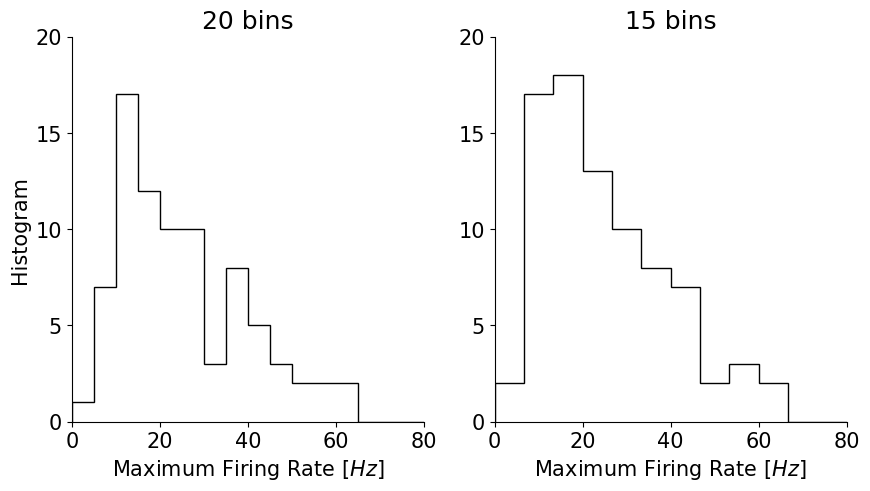

In [12]:
gs1 = gridspec.GridSpec(1,2)
fig1 = plt.figure(figsize = (10,5))
ax = plt.subplot(gs1[0])
ax1 = plt.subplot(gs1[1])

ax = plt.subplot(gs1[0])

# Maximum firing rate histogram

raw_tcs = np.unique(np.reshape(np.copy(data_dict['all_quad_raw_mean_tcs']), \
                               (np.prod(data_dict['all_quad_raw_mean_tcs'].shape[:2]), \
                                data_dict['all_quad_raw_mean_tcs'].shape[-1])),axis = 0)

ax.hist(raw_tcs.max(axis=1)/1.6, range = (0,100), bins = 20, histtype = 'step', \
              color = 'k')

ax.set_xticks(np.arange(0,81, 20))
ax.set_yticks(np.arange(0,21, 5))
ax.set_xlabel(r'Maximum Firing Rate [$Hz$]', size = 15)
ax.set_ylabel('Histogram', size = 15)
ax.set_xlim(0,80)
ax.set_ylim(0,20)
ax.set_title('20 bins')


ax1.hist(raw_tcs.max(axis=1)/1.6, range = (0,100), bins = 15, histtype = 'step', \
              color = 'k')

ax1.set_xticks(np.arange(0,81, 20))
ax1.set_yticks(np.arange(0,21, 5))
ax1.set_xlabel(r'Maximum Firing Rate [$Hz$]', size = 15)
ax1.set_xlim(0,80)
ax1.set_ylim(0,20)
ax1.set_title('15 bins')
fig1.savefig('C:/Users/Carlo PARIS/00PhD Code/DS_PCBreview/MaxTC_BINScomp.jpg', bbox_inches = 'tight', dpi = 300)

